# Exploraty Data Analysis (EDA): Bank Marketing

Each row of the dataset represents one bank client. The column y shows whether the client subscribed to the offer or not.

The goal is to understand the data, find and fix data quality issues, and discover which client characteristics are related to a positive answer ("yes"). These findings will then be used to develop the binary classifier in Task 3.

## Libraries and dataset

In [11]:
# import libraries
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [14]:
# load data
DATA_PATH = Path("../data/bank-full.csv")
df = pd.read_csv(DATA_PATH, sep=";")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


# Data exploration

## Data loading and integrity check

**Observations**
- No empty cells and no duplicate rows.
- "unknown" is a missing value in disguise: `poutcome` 81.7%, `contact` 28.8%, `education` 4.1%, `job` 0.6%.
- `default`, `housing`, `loan` and `y` have only two values (yes/no).
- `day` is stored as a number, but it is a day of the month.

In [16]:
# Let's check that the data has been loaded correctly.

integrity = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "empty_cells": df.isna().sum(),
    "unknown_values": (df == "unknown").sum(),
    "distinct_values": df.nunique(),
})
integrity["unknown_values_%"] = (integrity["unknown_values"] / len(df) * 100).round(1)
integrity

,type,empty_cells,unknown_values,distinct_values,unknown_values_%
age,int64,0,0,77,0.0
job,str,0,288,12,0.6
marital,str,0,0,3,0.0
education,str,0,1857,4,4.1
default,str,0,0,2,0.0
balance,int64,0,0,7168,0.0
housing,str,0,0,2,0.0
loan,str,0,0,2,0.0
contact,str,0,13020,3,28.8
day,int64,0,0,31,0.0


### Data dictionary

Source: `bank-names.txt`. One row = one client contacted by phone.
45,211 rows, 17 columns, no empty cells.

| # | Column | Meaning | Type | Values / range | Notes |
|---|---|---|---|---|---|
| 1 | `age` | Age of the client | Numeric | 18 – 95 | Median 39 |
| 2 | `job` | Type of job | Categorical | 12 values | 288 "unknown" |
| 3 | `marital` | Marital status | Categorical | married, single, divorced | "divorced" also means widowed |
| 4 | `education` | Education level | Categorical | primary, secondary, tertiary, unknown | 1,857 "unknown" |
| 5 | `default` | Has credit in default? | Binary | yes / no | 98% "no": little information |
| 6 | `balance` | Average yearly balance (EUR) | Numeric | −8,019 – 102,127 | Median 448: very skewed |
| 7 | `housing` | Has a housing loan? | Binary | yes / no | |
| 8 | `loan` | Has a personal loan? | Binary | yes / no | |
| 9 | `contact` | How the client was contacted | Categorical | cellular, telephone, unknown | 13,020 "unknown" |
| 10 | `day` | Day of the month of the last contact | Numeric | 1 – 31 | A calendar day, not a quantity |
| 11 | `month` | Month of the last contact | Categorical | jan – dec | No year in the data |
| 12 | `duration` | Length of the last call (seconds) | Numeric | 0 – 4,918 | Known only after the call: leakage, removed |
| 13 | `campaign` | Calls to this client in this campaign | Numeric | 1 – 63 | Median 2 |
| 14 | `pdays` | Days since the last contact in a previous campaign | Numeric | −1 – 871 | −1 = never contacted before |
| 15 | `previous` | Calls to this client before this campaign | Numeric | 0 – 275 | 275 looks like an error |
| 16 | `poutcome` | Result of the previous campaign | Categorical | success, failure, other, unknown | 36,959 "unknown" |
| 17 | `y` | **Target**: did the client subscribe a term deposit? | Binary | yes / no | 11.7% yes: unbalanced |

### Data quality checks

**Data quality**
- `pdays` = -1 for 36954 (81.7%). It means "never contacted before".
- One row was removed where `previous = 275` because it is probably an error, as this value is too high compared to the average."
- `duration` is known only after the call. I will not use it to predict. This is data leakage.
- The classes are unbalanced because only 11.7% of the clients said 'yes'.

In [3]:
never_contacted = (df["pdays"] == -1).sum()
print("pdays = -1:", never_contacted, f"({never_contacted / len(df) * 100:.1f}%)")

highest_previous = df["previous"].sort_values(ascending=False).head(5)
print("Highest 'previous':", highest_previous.tolist())

print(df.groupby("y")["duration"].median())

print("\nTarget:")
print(df["y"].value_counts(normalize=True).round(3))

pdays = -1: 36954 (81.7%)
Highest 'previous': [275, 58, 55, 51, 41]
y
no     164.0
yes    426.0
Name: duration, dtype: float64

Target:
y
no     0.883
yes    0.117
Name: proportion, dtype: float64


## Data cleaning

**Cleaning decisions**
- There are many unknown rows, and deleting them would remove too much data.
- A new column `contacted_before` was created because pdays uses the value -1 as a special code for `never contacted before`.
- One row was removed where `previous = 275` because it is probably an error, as this value is too high compared to the average."
- `duration` was removed because it is only known after the call, so it has no predictive value and causes data leakage
- `y` converted to True/False.

In [4]:
clean = df.copy()

clean["contacted_before"] = clean["pdays"] != -1
clean = clean[clean["previous"] != 275]
clean["y"] = clean["y"] == "yes"
clean = clean.drop(columns=["duration"])

display(len(df))
display(len(clean))

percentage = clean["y"].mean() * 100
print(f"Clients who said yes: {percentage:.1f}%")

45211

45210

Clients who said yes: 11.7%


## Exploratiy Data Analysis (EDA)
Goals:
- Study the features: distributions, typical values, ranges.
- Find relations between feature and the target.
- Find potential problems for the model: skweness, rare categories.

### Descriptive statistics and distributions

In [ ]:
# Descriptive statistics of numeric features
clean.describe().T

,count,mean,std,min,25%,50%,75%,max
age,45210.0,40.936231,10.618879,18.0,33.0,39.0,48.0,95.0
balance,45210.0,1362.290179,3044.797065,-8019.0,72.0,448.0,1428.0,102127.0
day,45210.0,15.806724,8.322315,1.0,8.0,16.0,21.0,31.0
campaign,45210.0,2.763858,3.098053,1.0,1.0,2.0,3.0,63.0
pdays,45210.0,40.192922,100.124419,-1.0,-1.0,-1.0,-1.0,871.0
previous,45210.0,0.574253,1.907928,0.0,0.0,0.0,0.0,58.0


**Distribution of the target variable "y"**

y
False    39921
True      5289
Name: count, dtype: int64


Text(0, 0.5, 'Number of clients')

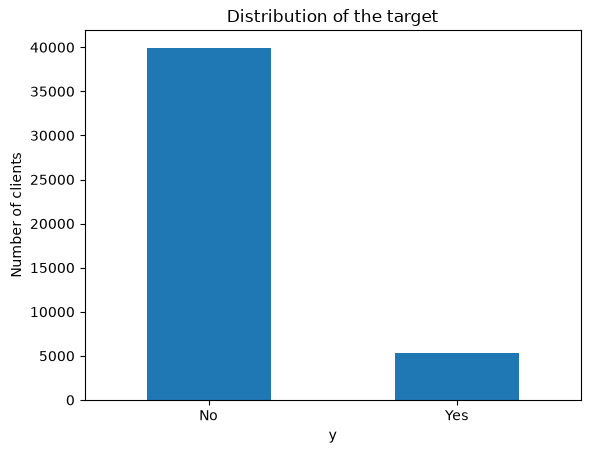

In [ ]:
counts = clean["y"].value_counts()
print(counts)

ax = counts.plot(kind="bar", title="Distribution of the target")
ax.set_xticklabels(["No", "Yes"], rotation=0)
ax.set_ylabel("Number of clients")

**Distribution of the numeric features**. We check if there are any asymmetries (skewness) and outliers.
- `campaign`, `previous`, and `balance`have a very strong positive skewness (a long tail on the right).

**Outliers in the numeric features**: boxplots and the IQR rule
  (a value is an outlier if it is below Q1 − 1.5·IQR or above Q3 + 1.5·IQR).
- In `age`, we do not have real outliers, just rare values.
- In `balance`, we have outliers for both very wealthy clients and those with a negative balance, which seems normal for a bank.
- In `campaign` and `previous` variables, I do not see any significant outliers either.



Text(0, 0.5, 'Number of clients')

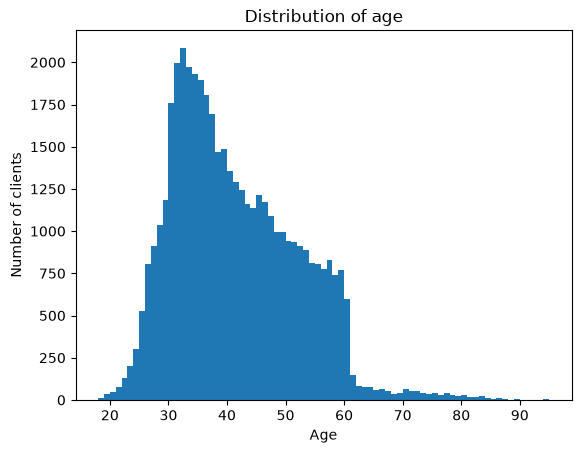

In [ ]:
ax = clean["age"].plot(kind="hist", bins=range(18,96), title="Distribution of age")
ax.set_xlabel("Age")
ax.set_ylabel("Number of clients")

Text(0, 0.5, 'Number of clients')

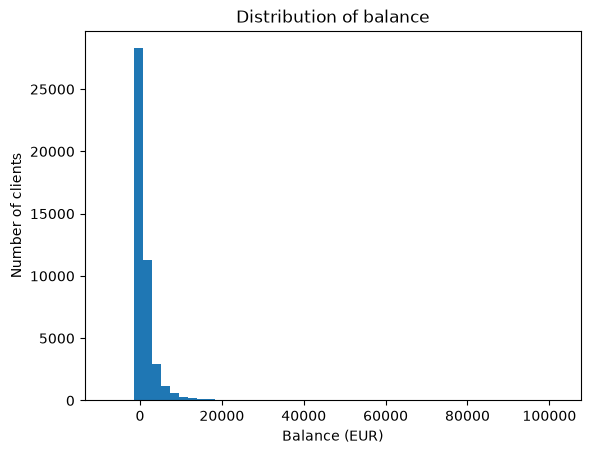

In [24]:
ax = clean["balance"].plot(kind="hist", bins=50, title="Distribution of balance")
ax.set_xlabel("Balance (EUR)")
ax.set_ylabel("Number of clients")

Text(0, 0.5, 'Number of clients')

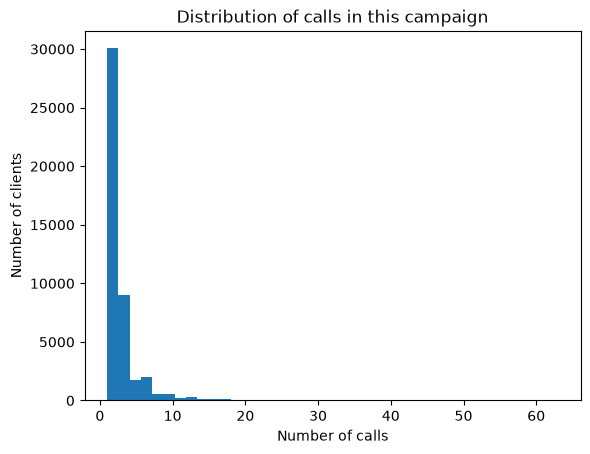

In [23]:
ax = clean["campaign"].plot(kind="hist", bins=40, title="Distribution of calls in this campaign")
ax.set_xlabel("Number of calls")
ax.set_ylabel("Number of clients")

In [ ]:
# Skewness: 0 = symmetric, above 1 = strong tail on the right
clean[["age", "balance", "campaign", "previous"]].skew().round(1)

age         0.7
balance     8.4
campaign    4.9
previous    7.8
dtype: float64

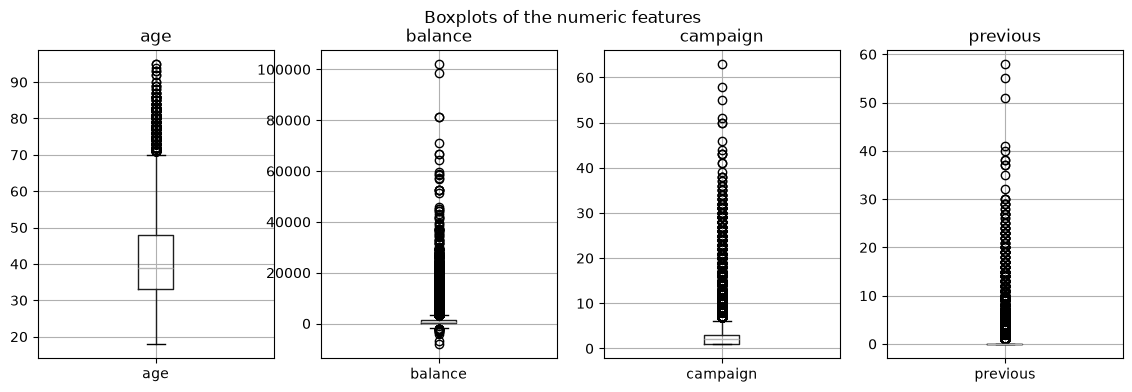

In [ ]:
# Outliers in the numeric features
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, column in zip(axes, ["age", "balance", "campaign", "previous"]):
    clean.boxplot(column=column, ax=ax)
    ax.set_title(column)
fig.suptitle("Boxplots of the numeric features")
plt.show()

In [34]:
columns = ["age", "balance", "campaign", "previous"]
q1 = clean[columns].quantile(0.25)
q3 = clean[columns].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outliers = ((clean[columns] < lower) | (clean[columns] > upper)).sum()

pd.DataFrame({
    "lower": lower,
    "upper": upper,
    "outliers": outliers,
    "outliers_%": (outliers / len(clean) * 100).round(1),
})

,lower,upper,outliers,outliers_%
age,10.5,70.5,487,1.1
balance,-1962.0,3462.0,4729,10.5
campaign,-2.0,6.0,3064,6.8
previous,0.0,0.0,8256,18.3


**Distribution of the categorical features**
- Calls are concentrated between May and August.
- The main category is blue-collar workers (9,732).
- Most clients did not participate in previous campaigns. This can be seen from the unknown value at 81.7%.

month
jan     1403
feb     2648
mar      477
apr     2932
may    13766
jun     5341
jul     6895
aug     6247
sep      579
oct      738
nov     3970
dec      214
Name: count, dtype: int64


Text(0, 0.5, 'Number of clients')

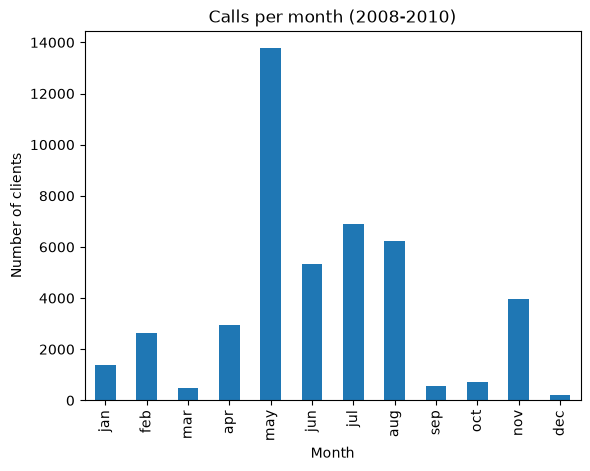

In [30]:
month_order = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
calls_per_month = clean["month"].value_counts().reindex(month_order)
print(calls_per_month)

ax = calls_per_month.plot(kind="bar", title="Calls per month (2008-2010)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of clients")

job
blue-collar      9732
management       9457
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64


Text(0.5, 0, 'Number of clients')

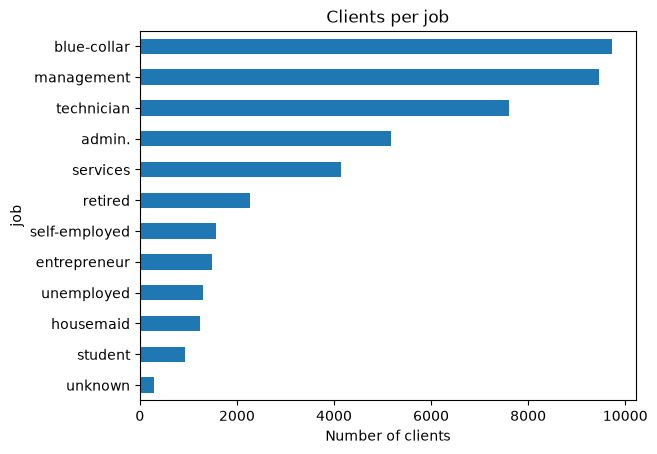

In [29]:
print(clean["job"].value_counts())

ax = clean["job"].value_counts().sort_values().plot(kind="barh", title="Clients per job")
ax.set_xlabel("Number of clients")

poutcome
unknown    36959
failure     4901
other       1839
success     1511
Name: count, dtype: int64
poutcome
unknown    81.7
failure    10.8
other       4.1
success     3.3
Name: count, dtype: float64


Text(0.5, 0, 'Number of clients')

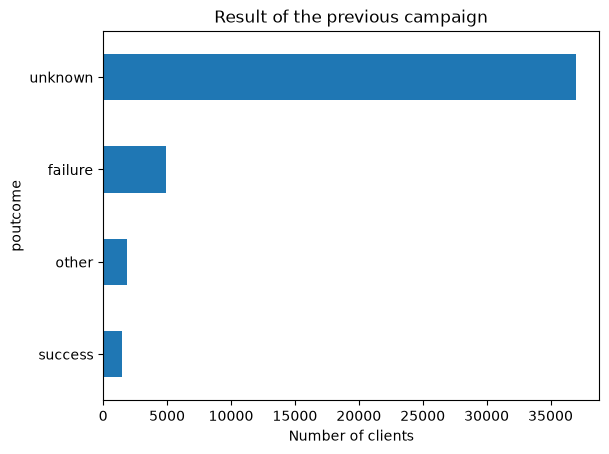

In [31]:
counts = clean["poutcome"].value_counts()
print(counts)
print((counts / len(clean) * 100).round(1))

ax = counts.sort_values().plot(kind="barh", title="Result of the previous campaign")
ax.set_xlabel("Number of clients")

default
no     44395
yes      815
Name: count, dtype: int64
default
no     98.2
yes     1.8
Name: count, dtype: float64


Text(0, 0.5, 'Number of clients')

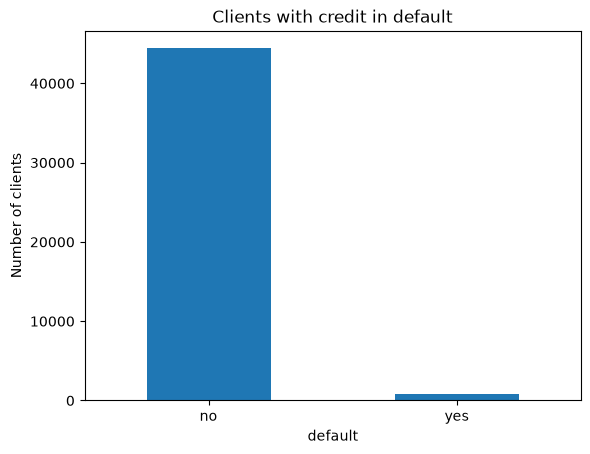

In [32]:
counts = clean["default"].value_counts()
print(counts)
print((counts / len(clean) * 100).round(1))

ax = counts.plot(kind="bar", title="Clients with credit in default")
ax.set_xticklabels(counts.index, rotation=0)
ax.set_ylabel("Number of clients")

## Relations between variables and target

--------------

poutcome
failure    12.6
other      16.7
success    64.7
unknown     9.2
Name: y, dtype: float64
poutcome
unknown    36959
failure     4901
other       1839
success     1511
Name: count, dtype: int64


Text(0.5, 0, 'Clients who said yes (%)')

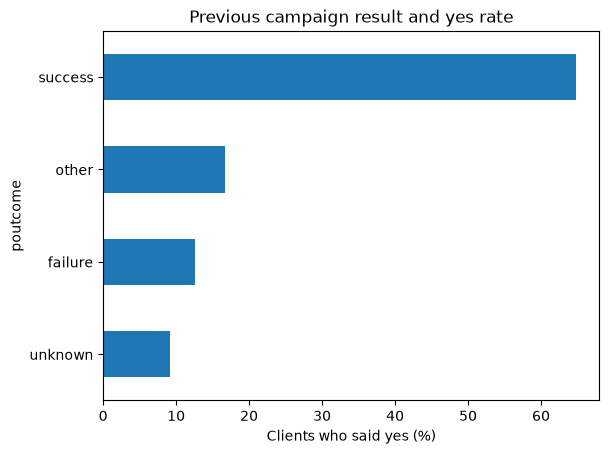

In [5]:
rate = clean.groupby("poutcome")["y"].mean() * 100
print(rate.round(1))
print(clean["poutcome"].value_counts())

ax = rate.sort_values().plot(kind="barh", title="Previous campaign result and yes rate")
ax.set_xlabel("Clients who said yes (%)")

job
admin.           12.2
blue-collar       7.3
entrepreneur      8.3
housemaid         8.8
management       13.8
retired          22.8
self-employed    11.8
services          8.9
student          28.7
technician       11.1
unemployed       15.5
unknown          11.8
Name: y, dtype: float64
job
blue-collar      9732
management       9457
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64


Text(0.5, 0, 'Clients who said yes (%)')

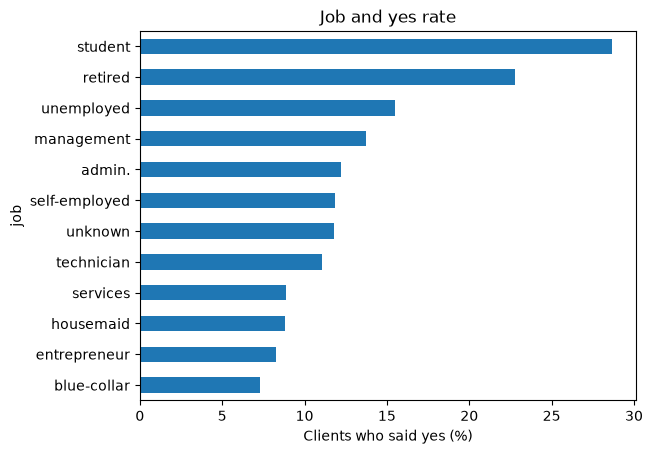

In [6]:
rate = clean.groupby("job")["y"].mean() * 100
print(rate.round(1))
print(clean["job"].value_counts())

ax = rate.sort_values().plot(kind="barh", title="Job and yes rate")
ax.set_xlabel("Clients who said yes (%)")

calls
1      14.6
2      11.2
3      11.2
4-5     8.6
6+      5.8
Name: y, dtype: float64
calls
1      17544
2      12504
3       5521
4-5     5286
6+      4355
Name: count, dtype: int64


Text(0, 0.5, 'Clients who said yes (%)')

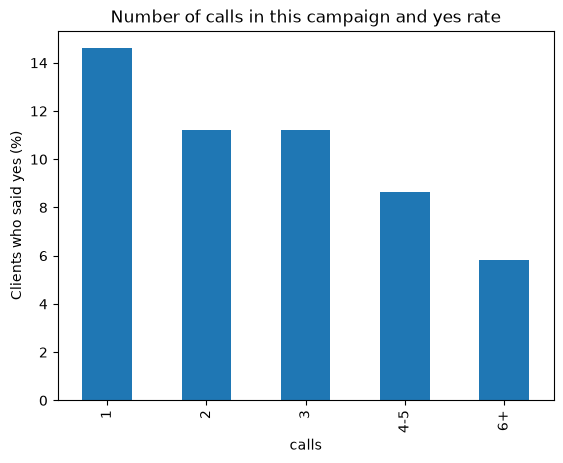

In [7]:
# Group the number of calls into bands: 1, 2, 3, 4-5, 6 or more
clean["calls"] = pd.cut(clean["campaign"], bins=[0, 1, 2, 3, 5, 100],
                        labels=["1", "2", "3", "4-5", "6+"])

rate = clean.groupby("calls")["y"].mean() * 100
print(rate.round(1))
print(clean["calls"].value_counts())

ax = rate.plot(kind="bar", title="Number of calls in this campaign and yes rate")
ax.set_ylabel("Clients who said yes (%)")

Text(0.5, 0, 'Balance (EUR)')

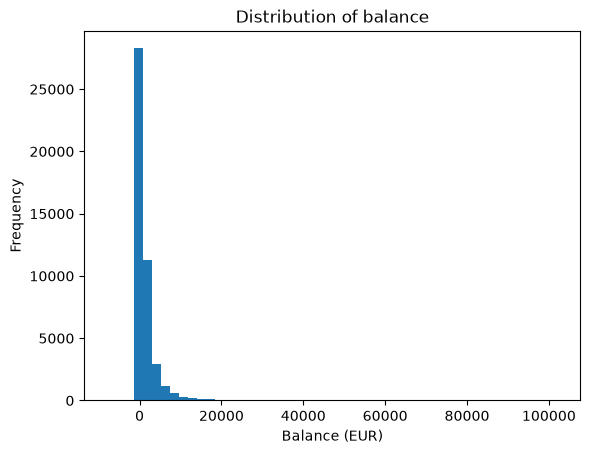

In [8]:
ax = clean["balance"].plot(kind="hist", bins=50, title="Distribution of balance")
ax.set_xlabel("Balance (EUR)")

Text(0.5, 0, 'Age')

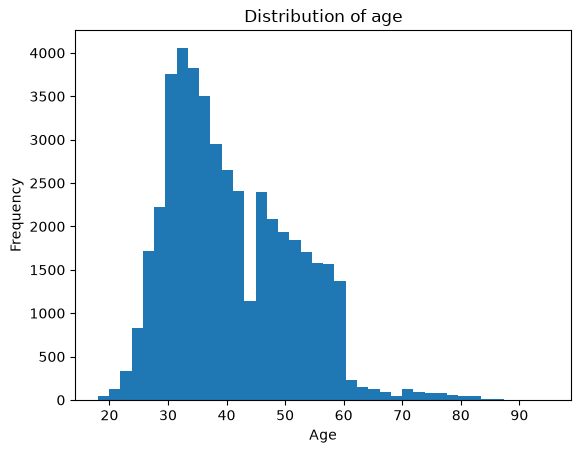

In [9]:
ax = clean["age"].plot(kind="hist", bins=40, title="Distribution of age")
ax.set_xlabel("Age")

In [10]:
numbers = clean[["age", "balance", "day", "campaign", "previous", "y"]].astype(float)
print(numbers.corr()["y"].round(3))

age         0.025
balance     0.053
day        -0.028
campaign   -0.073
previous    0.114
y           1.000
Name: y, dtype: float64
